In [0]:
%sql
show catalogs


catalog
samples
system
workspace


In [0]:
%sql
show schemas


databaseName
default
information_schema


In [0]:
%sql
use catalog workspace;

In [0]:
%sql
use schema default;

In [0]:
%sql
show tables;


database,tableName,isTemporary
default,bronze_parking,false
default,completed_parking_view,false
default,confirmed_event_registrations,false
default,event_log_f48a1fd7_3295_44dd_a09f_93ddd42a0080,false
default,event_master,false
default,event_registrations_source,false
default,event_registrations_work,false
default,event_revenue_view,false
default,parking_sessions_source,false
default,parking_sessions_work,false


In [0]:
%sql
SELECT * FROM tp_entries_raw;


entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1001,V515,A08,2026-10-06,17:20:00,15,20,Standard,350.0,Cancelled,App
1002,V535,A01,2026-10-10,15:00:00,65,6,Standard,350.0,Completed,App
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,350.0,Completed,Web
1004,V517,A05,2026-10-15,17:50:00,20,6,Express,650.0,Completed,Web
1005,V537,A07,2026-10-07,16:50:00,5,6,Standard,350.0,Completed,Kiosk
1006,V549,A08,2026-10-09,10:30:00,10,8,VIP,900.0,Completed,Web
1007,V529,A08,2026-10-14,14:50:00,5,20,Standard,350.0,Completed,Web
1008,V521,A06,2026-10-01,13:40:00,40,6,Express,650.0,Completed,Kiosk
1009,V510,A02,2026-10-16,16:00:00,10,8,Standard,350.0,Completed,null
1010,V560,A02,2026-10-09,11:10:00,15,12,Express,600.0,Cancelled,Kiosk


In [0]:
%sql
SELECT * FROM tp_maintenance;

maintenance_id,attraction_id,maintenance_date,issue_type,downtime_minutes,maintenance_status
M001,A05,2026-10-15,Cleaning,90,Scheduled
M002,A08,2026-10-05,Mechanical,60,Completed
M003,A02,2026-10-12,Mechanical,0,Scheduled
M004,A09,2026-10-18,Electrical,0,Open
M005,A05,2026-10-12,Electrical,0,Scheduled
M006,A04,2026-10-07,Water System,45,Completed
M007,A10,2026-10-20,Mechanical,120,Completed
M008,A04,2026-10-04,Water System,90,Open
M009,A08,2026-10-19,Safety Check,30,Scheduled
M010,A02,2026-10-15,Safety Check,0,Open


In [0]:
%sql
SELECT * FROM tp_attractions;

attraction_id,attraction_name,capacity_per_hour,category,features,is_active,location,min_height_cm,opened_year
A01,Sky Spinner,140,Thrill,"List(Outdoor, High Speed)",true,"List(N1, North)",120,2018
A02,Coral Carousel,200,Family,"List(Indoor, Family Friendly)",true,"List(E2, East)",0,2015
A03,Jungle Rapids,110,Water,"List(Water Ride, Outdoor)",true,"List(S1, South)",110,2020
A04,Moonlight Train,180,Family,"List(Scenic, Family Friendly)",true,"List(W3, West)",0,2012
A05,Meteor Drop,100,Thrill,"List(High Speed, Outdoor)",true,"List(N2, North)",135,2022
A06,Pirate Voyage,130,Water,"List(Water Ride, Themed)",true,"List(E1, East)",100,2019
A07,Crystal Maze,160,Adventure,"List(Indoor, Puzzle)",true,"List(S3, South)",90,2021
A08,Forest Flyers,120,Adventure,"List(Outdoor, Interactive)",true,"List(W1, West)",115,2023
A09,Galaxy Theater,260,Show,"List(Indoor, Live Show)",true,"List(N3, North)",0,2017
A10,Mini Explorers,190,Family,"List(Kids, Indoor)",true,"List(E3, East)",0,2016


In [0]:
%sql
SELECT * FROM tp_entry_changes;

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,400.0,Completed,App
1010,V560,A02,2026-10-09,11:10:00,15,12,Express,675.0,Completed,App
1040,V514,A03,2026-10-01,19:10:00,5,15,Standard,500.0,Completed,App
1068,V531,A10,2026-10-15,16:20:00,30,4,Express,725.0,Completed,App
1095,V563,A07,2026-10-09,11:20:00,75,4,Standard,500.0,Completed,App
1121,V700,A01,2026-10-20,11:00:00,15,8,Standard,350.0,Completed,Web
1122,V701,A02,2026-10-20,12:00:00,20,10,Express,600.0,Completed,Web
1123,V702,A03,2026-10-20,13:00:00,25,12,Standard,350.0,Completed,Web
1124,V703,A04,2026-10-20,14:00:00,30,14,Express,600.0,Completed,Web
1125,V704,A05,2026-10-20,15:00:00,35,16,Standard,350.0,Completed,Web


In [0]:
%sql

SELECT COUNT(*) AS total_rows FROM tp_entries_raw;

total_rows
121


In [0]:
%sql
SELECT COUNT(*) AS total_rows FROM tp_attractions;

total_rows
10


In [0]:
%sql

SELECT COUNT(*) AS total_rows FROM tp_maintenance;

total_rows
28


In [0]:
%sql

SELECT COUNT(*) AS total_rows FROM tp_entry_changes;

total_rows
10


In [0]:
%sql
DESCRIBE DETAIL tp_entries_raw;

format,id,name,description,location,createdAt,lastModified,partitionColumns,clusteringColumns,numFiles,sizeInBytes,properties,minReaderVersion,minWriterVersion,tableFeatures,statistics,clusterByAuto
delta,d392aef9-ca4e-486f-bf24-57fb70e0d654,workspace.default.tp_entries_raw,null,,2026-11-11T05:22:01.500Z,2026-11-11T05:22:07.000Z,List(),List(),1,4632,"Map(delta.parquet.format.version -> 2.12.0, delta.parquet.format.version.afe.internal -> 2.12.0, delta.parquet.compression.codec -> zstd, delta.enableDeletionVectors -> true)",3,7,"List(appendOnly, deletionVectors, invariants)","Map(numRowsDeletedByDeletionVectors -> 0, numDeletionVectors -> 0)",false


In [0]:
%sql
SELECT
    entry_id,
    attraction_id,
    visit_date,
    ticket_type,
    ticket_price
FROM tp_entries_raw
LIMIT 20;

entry_id,attraction_id,visit_date,ticket_type,ticket_price
1001,A08,2026-10-06,Standard,350.0
1002,A01,2026-10-10,Standard,350.0
1003,A04,2026-10-11,Standard,350.0
1004,A05,2026-10-15,Express,650.0
1005,A07,2026-10-07,Standard,350.0
1006,A08,2026-10-09,VIP,900.0
1007,A08,2026-10-14,Standard,350.0
1008,A06,2026-10-01,Express,650.0
1009,A02,2026-10-16,Standard,350.0
1010,A02,2026-10-09,Express,600.0


In [0]:
%sql
SELECT *
FROM tp_entries_raw
WHERE status = 'Completed'
  AND ticket_price > 500;

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1004,V517,A05,2026-10-15,17:50:00,20,6,Express,650.0,Completed,Web
1006,V549,A08,2026-10-09,10:30:00,10,8,VIP,900.0,Completed,Web
1008,V521,A06,2026-10-01,13:40:00,40,6,Express,650.0,Completed,Kiosk
1014,V564,A07,2026-10-01,14:10:00,65,4,VIP,900.0,Completed,Partner
1018,V535,A10,2026-10-01,13:10:00,65,8,Express,600.0,Completed,App
1021,V527,A03,2026-10-02,13:00:00,-8,8,Express,650.0,Completed,Web
1022,V543,A09,2026-10-15,17:20:00,65,4,Express,600.0,Completed,App
1024,V537,A06,2026-10-06,17:30:00,50,8,Express,650.0,Completed,Web
1025,V513,A09,2026-10-08,14:20:00,65,12,Express,600.0,Completed,App
1028,V547,A08,2026-10-02,13:20:00,75,12,Express,600.0,Completed,App


In [0]:
%sql
SELECT DISTINCT ticket_type
FROM tp_entries_raw;

ticket_type
Standard
Express
VIP


In [0]:
%sql
SELECT DISTINCT booking_channel
FROM tp_entries_raw;

booking_channel
App
Web
Kiosk
Partner
null


In [0]:
%sql
SELECT *
FROM tp_entries_raw
WHERE booking_channel IN ('Online', 'Mobile App');

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel


In [0]:
%sql
SELECT
    TO_DATE(visit_date) AS visit_dt,
    COUNT(*) AS total_entries
FROM tp_entries_raw
GROUP BY TO_DATE(visit_date)
ORDER BY visit_dt;

visit_dt,total_entries
2026-10-01,11
2026-10-02,4
2026-10-03,13
2026-10-04,7
2026-10-05,4
2026-10-06,6
2026-10-07,8
2026-10-08,7
2026-10-09,10
2026-10-10,7


In [0]:
from pyspark.sql.functions import *

entries_df = spark.table("tp_entries_raw")
attractions_df = spark.table("tp_attractions")

In [0]:
entries_df.filter(
    col("ticket_price").isNull() |
    col("booking_channel").isNull()
).show(truncate=False)

+--------+----------+-------------+----------+----------+------------+------------+-----------+------------+---------+---------------+
|entry_id|visitor_id|attraction_id|visit_date|entry_time|wait_minutes|ride_minutes|ticket_type|ticket_price|status   |booking_channel|
+--------+----------+-------------+----------+----------+------------+------------+-----------+------------+---------+---------------+
|1009    |V510      |A02          |2026-10-16|16:00:00  |10          |8           |Standard   |350.0       |Completed|NULL           |
|1016    |V563      |A10          |2026-10-08|15:10:00  |30          |10          |Standard   |NULL        |Completed|Kiosk          |
|1040    |V514      |A03          |2026-10-01|19:10:00  |5           |15          |Standard   |400.0       |Completed|NULL           |
|1071    |V553      |A07          |2026-10-03|11:10:00  |5           |20          |Standard   |NULL        |Completed|Partner        |
|1087    |V537      |A01          |2026-10-11|10:00:00 

In [0]:
clean_df = entries_df.na.fill({
    "booking_channel": "Unknown"
})

clean_df.show()

+--------+----------+-------------+----------+----------+------------+------------+-----------+------------+---------+---------------+
|entry_id|visitor_id|attraction_id|visit_date|entry_time|wait_minutes|ride_minutes|ticket_type|ticket_price|   status|booking_channel|
+--------+----------+-------------+----------+----------+------------+------------+-----------+------------+---------+---------------+
|    1001|      V515|          A08|2026-10-06|  17:20:00|          15|          20|   Standard|       350.0|Cancelled|            App|
|    1002|      V535|          A01|2026-10-10|  15:00:00|          65|           6|   Standard|       350.0|Completed|            App|
|    1003|      V547|          A04|2026-10-11|  11:00:00|          40|          15|   Standard|       350.0|Completed|            Web|
|    1004|      V517|          A05|2026-10-15|  17:50:00|          20|           6|    Express|       650.0|Completed|            Web|
|    1005|      V537|          A07|2026-10-07|  16:50:0

In [0]:
invalid_df = entries_df.filter(
    (col("wait_minutes") < 0) |
    (col("ride_minutes") <= 0) |
    (col("ticket_price") <= 0)
)

invalid_df.show(truncate=False)

+--------+----------+-------------+----------+----------+------------+------------+-----------+------------+---------+---------------+
|entry_id|visitor_id|attraction_id|visit_date|entry_time|wait_minutes|ride_minutes|ticket_type|ticket_price|status   |booking_channel|
+--------+----------+-------------+----------+----------+------------+------------+-----------+------------+---------+---------------+
|1021    |V527      |A03          |2026-10-02|13:00:00  |-8          |8           |Express    |650.0       |Completed|Web            |
|1036    |V527      |A06          |2026-10-04|14:40:00  |40          |0           |Standard   |400.0       |Completed|Kiosk          |
|1058    |V516      |A02          |2026-10-08|19:10:00  |30          |4           |Standard   |0.0         |Completed|App            |
|1073    |V501      |A03          |2026-10-07|18:50:00  |-3          |6           |Express    |650.0       |Completed|App            |
+--------+----------+-------------+----------+---------

In [0]:
entries_df.groupBy("entry_id") \
    .count() \
    .filter(col("count") > 1) \
    .show()

+--------+-----+
|entry_id|count|
+--------+-----+
|    1032|    2|
+--------+-----+



In [0]:
dedup_df = entries_df.dropDuplicates(["entry_id"])

dedup_df.show()


+--------+----------+-------------+----------+----------+------------+------------+-----------+------------+---------+---------------+
|entry_id|visitor_id|attraction_id|visit_date|entry_time|wait_minutes|ride_minutes|ticket_type|ticket_price|   status|booking_channel|
+--------+----------+-------------+----------+----------+------------+------------+-----------+------------+---------+---------------+
|    1001|      V515|          A08|2026-10-06|  17:20:00|          15|          20|   Standard|       350.0|Cancelled|            App|
|    1002|      V535|          A01|2026-10-10|  15:00:00|          65|           6|   Standard|       350.0|Completed|            App|
|    1003|      V547|          A04|2026-10-11|  11:00:00|          40|          15|   Standard|       350.0|Completed|            Web|
|    1004|      V517|          A05|2026-10-15|  17:50:00|          20|           6|    Express|       650.0|Completed|            Web|
|    1005|      V537|          A07|2026-10-07|  16:50:0

In [0]:
missing_attraction_df = entries_df.join(
    attractions_df,
    "attraction_id",
    "left_anti"
)

missing_attraction_df.show(truncate=False)

+-------------+--------+----------+----------+----------+------------+------------+-----------+------------+---------+---------------+
|attraction_id|entry_id|visitor_id|visit_date|entry_time|wait_minutes|ride_minutes|ticket_type|ticket_price|status   |booking_channel|
+-------------+--------+----------+----------+----------+------------+------------+-----------+------------+---------+---------------+
|A99          |1092    |V566      |2026-10-03|15:40:00  |75          |20          |Standard   |400.0       |Completed|Kiosk          |
+-------------+--------+----------+----------+----------+------------+------------+-----------+------------+---------+---------------+



In [0]:
wait_df = entries_df.filter(col("wait_minutes") >= 0)

wait_df = wait_df.withColumn(
    "wait_category",
    when(col("wait_minutes").between(0, 20), "Short")
    .when(col("wait_minutes").between(21, 45), "Medium")
    .otherwise("Long")
)

wait_df.select(
    "entry_id",
    "wait_minutes",
    "wait_category"
).show()


+--------+------------+-------------+
|entry_id|wait_minutes|wait_category|
+--------+------------+-------------+
|    1001|          15|        Short|
|    1002|          65|         Long|
|    1003|          40|       Medium|
|    1004|          20|        Short|
|    1005|           5|        Short|
|    1006|          10|        Short|
|    1007|           5|        Short|
|    1008|          40|       Medium|
|    1009|          10|        Short|
|    1010|          15|        Short|
|    1011|          25|       Medium|
|    1012|          25|       Medium|
|    1013|          15|        Short|
|    1014|          65|         Long|
|    1015|          10|        Short|
|    1016|          30|       Medium|
|    1017|          40|       Medium|
|    1018|          65|         Long|
|    1019|          15|        Short|
|    1020|          10|        Short|
+--------+------------+-------------+
only showing top 20 rows


In [0]:
joined_df = entries_df.join(
    attractions_df,
    "attraction_id",
    "left"
)

joined_df.select(
    "entry_id",
    "attraction_id",
    "attraction_name",
    col("location.zone").alias("zone"),
    "features"
).show(truncate=False)

+--------+-------------+---------------+-----+-------------------------+
|entry_id|attraction_id|attraction_name|zone |features                 |
+--------+-------------+---------------+-----+-------------------------+
|1001    |A08          |Forest Flyers  |West |[Outdoor, Interactive]   |
|1002    |A01          |Sky Spinner    |North|[Outdoor, High Speed]    |
|1003    |A04          |Moonlight Train|West |[Scenic, Family Friendly]|
|1004    |A05          |Meteor Drop    |North|[High Speed, Outdoor]    |
|1005    |A07          |Crystal Maze   |South|[Indoor, Puzzle]         |
|1006    |A08          |Forest Flyers  |West |[Outdoor, Interactive]   |
|1007    |A08          |Forest Flyers  |West |[Outdoor, Interactive]   |
|1008    |A06          |Pirate Voyage  |East |[Water Ride, Themed]     |
|1009    |A02          |Coral Carousel |East |[Indoor, Family Friendly]|
|1010    |A02          |Coral Carousel |East |[Indoor, Family Friendly]|
|1011    |A02          |Coral Carousel |East |[Indo

In [0]:
%sql
SELECT *
FROM tp_entries_raw
WHERE status = 'Completed'
  AND ticket_type IN ('Standard', 'Express')
  AND ticket_price BETWEEN 100 AND 1000;

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1002,V535,A01,2026-10-10,15:00:00,65,6,Standard,350.0,Completed,App
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,350.0,Completed,Web
1004,V517,A05,2026-10-15,17:50:00,20,6,Express,650.0,Completed,Web
1005,V537,A07,2026-10-07,16:50:00,5,6,Standard,350.0,Completed,Kiosk
1007,V529,A08,2026-10-14,14:50:00,5,20,Standard,350.0,Completed,Web
1008,V521,A06,2026-10-01,13:40:00,40,6,Express,650.0,Completed,Kiosk
1009,V510,A02,2026-10-16,16:00:00,10,8,Standard,350.0,Completed,null
1013,V506,A09,2026-10-11,10:20:00,15,20,Standard,350.0,Completed,Web
1015,V529,A05,2026-10-01,13:40:00,10,15,Standard,400.0,Completed,Kiosk
1017,V501,A10,2026-10-06,17:50:00,40,8,Standard,350.0,Completed,Partner


In [0]:
%sql
SELECT
    attraction_id,
    COUNT(*) AS completed_entries,
    SUM(ticket_price) AS total_revenue
FROM tp_entries_raw
WHERE status = 'Completed'
  AND ticket_price > 0
GROUP BY attraction_id
ORDER BY total_revenue DESC;

attraction_id,completed_entries,total_revenue
A10,13,6050.0
A05,10,5850.0
A04,12,5450.0
A07,9,4750.0
A06,9,4600.0
A03,8,4500.0
A01,9,4200.0
A08,8,3600.0
A09,7,3200.0
A02,5,2000.0


In [0]:
%sql
SELECT
    a.category,
    ROUND(AVG(e.wait_minutes),2) AS avg_wait_time
FROM tp_entries_raw e
JOIN tp_attractions a
ON e.attraction_id = a.attraction_id
WHERE e.wait_minutes >= 0
GROUP BY a.category
ORDER BY avg_wait_time DESC;

category,avg_wait_time
Show,35.91
Adventure,33.96
Family,31.46
Thrill,30.5
Water,25.23


In [0]:
%sql
SELECT
    a.attraction_name,
    SUM(m.downtime_minutes) AS total_downtime
FROM tp_maintenance m
JOIN tp_attractions a
ON m.attraction_id = a.attraction_id
WHERE m.maintenance_status = 'Completed'
GROUP BY a.attraction_name
ORDER BY total_downtime DESC;

attraction_name,total_downtime
Coral Carousel,240
Pirate Voyage,135
Mini Explorers,120
Crystal Maze,120
Sky Spinner,120
Moonlight Train,75
Forest Flyers,60
Jungle Rapids,30
Galaxy Theater,0


num_affected_rows,num_inserted_rows


In [0]:
entries_df = spark.table("tp_entries_raw")

entries_df.write \
    .format("delta") \
    .mode("overwrite") \
    .saveAsTable("tp_entries_work_df")

In [0]:
%sql
DESCRIBE tp_entries_work;

col_name,data_type,comment
entry_id,int,null
visitor_id,string,null
attraction_id,string,null
visit_date,string,null
entry_time,string,null
wait_minutes,int,null
ride_minutes,int,null
ticket_type,string,null
ticket_price,double,null
status,string,null


In [0]:
%sql
INSERT INTO tp_entries_work
VALUES
(
  1001,
  'V201',
  'A001',
  '2026-11-11',
  '09:15',
  20,
  8,
  'Standard',
  600,
  'Online',
  'Completed'
),
(
  1002,
  'V202',
  'A002',
  '2026-11-11',
  '10:30',
  15,
  12,
  'Express',
  900,
  'Mobile App',
  'Completed'
);

num_affected_rows,num_inserted_rows
2,2


In [0]:
%sql
UPDATE tp_entries_work
SET
    status = 'Completed',
    ticket_price = 850
WHERE entry_id = 1001;

num_affected_rows
2


In [0]:
%sql
DELETE FROM tp_entries_work
WHERE status = 'Cancelled';

num_affected_rows
15


In [0]:
%sql
DESCRIBE EXTENDED tp_entries_work;

col_name,data_type,comment
entry_id,int,null
visitor_id,string,null
attraction_id,string,null
visit_date,string,null
entry_time,string,null
wait_minutes,int,null
ride_minutes,int,null
ticket_type,string,null
ticket_price,double,null
status,string,null


In [0]:
%sql
SELECT *
FROM tp_entry_changes;

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,400.0,Completed,App
1010,V560,A02,2026-10-09,11:10:00,15,12,Express,675.0,Completed,App
1040,V514,A03,2026-10-01,19:10:00,5,15,Standard,500.0,Completed,App
1068,V531,A10,2026-10-15,16:20:00,30,4,Express,725.0,Completed,App
1095,V563,A07,2026-10-09,11:20:00,75,4,Standard,500.0,Completed,App
1121,V700,A01,2026-10-20,11:00:00,15,8,Standard,350.0,Completed,Web
1122,V701,A02,2026-10-20,12:00:00,20,10,Express,600.0,Completed,Web
1123,V702,A03,2026-10-20,13:00:00,25,12,Standard,350.0,Completed,Web
1124,V703,A04,2026-10-20,14:00:00,30,14,Express,600.0,Completed,Web
1125,V704,A05,2026-10-20,15:00:00,35,16,Standard,350.0,Completed,Web


In [0]:
%sql
MERGE INTO tp_entries_work tgt
USING tp_entry_changes src
ON tgt.entry_id = src.entry_id

WHEN MATCHED THEN
UPDATE SET
  tgt.visitor_id      = src.visitor_id,
  tgt.attraction_id   = src.attraction_id,
  tgt.visit_date      = src.visit_date,
  tgt.entry_time      = src.entry_time,
  tgt.wait_minutes    = src.wait_minutes,
  tgt.ride_minutes    = src.ride_minutes,
  tgt.ticket_type     = src.ticket_type,
  tgt.ticket_price    = src.ticket_price,
  tgt.booking_channel = src.booking_channel,
  tgt.status          = src.status

WHEN NOT MATCHED THEN
INSERT *;

num_affected_rows,num_updated_rows,num_deleted_rows,num_inserted_rows
10,4,0,6


In [0]:
%sql
SELECT t.*
FROM tp_entries_work t
JOIN tp_entry_changes c
ON t.entry_id = c.entry_id;

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,400.0,Completed,App
1010,V560,A02,2026-10-09,11:10:00,15,12,Express,675.0,Completed,App
1040,V514,A03,2026-10-01,19:10:00,5,15,Standard,500.0,Completed,App
1068,V531,A10,2026-10-15,16:20:00,30,4,Express,725.0,Completed,App
1095,V563,A07,2026-10-09,11:20:00,75,4,Standard,500.0,Completed,App
1121,V700,A01,2026-10-20,11:00:00,15,8,Standard,350.0,Completed,Web
1122,V701,A02,2026-10-20,12:00:00,20,10,Express,600.0,Completed,Web
1123,V702,A03,2026-10-20,13:00:00,25,12,Standard,350.0,Completed,Web
1124,V703,A04,2026-10-20,14:00:00,30,14,Express,600.0,Completed,Web
1125,V704,A05,2026-10-20,15:00:00,35,16,Standard,350.0,Completed,Web


In [0]:
%sql DESCRIBE HISTORY tp_entries_work;

version,timestamp,userId,userName,operation,operationParameters,job,notebook,queryHistoryStatementId,clusterId,readVersion,isolationLevel,isBlindAppend,operationMetrics,userMetadata,engineInfo
6,2026-11-11T06:23:30.000Z,70638158589839,kishorekarthick0803@gmail.com,MERGE,"Map(predicate -> [""(entry_id#20487 = entry_id#20498)""], clusterBy -> [], matchedPredicates -> [{""actionType"":""update""}], statsOnLoad -> true, notMatchedBySourcePredicates -> [], notMatchedPredicates -> [{""actionType"":""insert""}])",null,List(3535405419426731),a04a21e5-7730-491f-905d-e4574dffa3e9,1111-050729-5fwjdjgl-v2n,5,WriteSerializable,false,"Map(numTargetRowsCopied -> 0, numTargetRowsDeleted -> 0, numTargetFilesAdded -> 1, numTargetBytesAdded -> 3575, numTargetBytesRemoved -> 0, numTargetDeletionVectorsAdded -> 1, numTargetRowsMatchedUpdated -> 4, executionTimeMs -> 3094, materializeSourceTimeMs -> 6, numTargetRowsInserted -> 6, numTargetRowsMatchedDeleted -> 0, numTargetDeletionVectorsUpdated -> 0, scanTimeMs -> 1030, numTargetRowsUpdated -> 4, numOutputRows -> 10, numTargetDeletionVectorsRemoved -> 0, numTargetRowsNotMatchedBySourceUpdated -> 0, numTargetChangeFilesAdded -> 0, numSourceRows -> 10, numTargetFilesRemoved -> 0, numTargetRowsNotMatchedBySourceDeleted -> 0, rewriteTimeMs -> 1992)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
5,2026-11-11T06:20:59.000Z,70638158589839,kishorekarthick0803@gmail.com,OPTIMIZE,"Map(predicate -> [], auto -> true, clusterBy -> [], zOrderBy -> [], batchId -> 0)",null,List(3535405419426731),05613724-f123-4d2b-b124-d43db11530c0,1111-050729-5fwjdjgl-v2n,4,SnapshotIsolation,false,"Map(numRemovedFiles -> 1, numRemovedBytes -> 4739, p25FileSize -> 4668, numDeletionVectorsRemoved -> 1, minFileSize -> 4668, numAddedFiles -> 1, maxFileSize -> 4668, p75FileSize -> 4668, p50FileSize -> 4668, numAddedBytes -> 4668)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
4,2026-11-11T06:20:58.000Z,70638158589839,kishorekarthick0803@gmail.com,DELETE,"Map(predicate -> [""(status#19795 = Cancelled)""])",null,List(3535405419426731),05613724-f123-4d2b-b124-d43db11530c0,1111-050729-5fwjdjgl-v2n,3,WriteSerializable,false,"Map(numRemovedFiles -> 0, numRemovedBytes -> 0, numCopiedRows -> 0, numDeletionVectorsAdded -> 1, numDeletionVectorsRemoved -> 0, numAddedChangeFiles -> 0, executionTimeMs -> 1055, numDeletionVectorsUpdated -> 0, numDeletedRows -> 15, scanTimeMs -> 645, numAddedFiles -> 0, numAddedBytes -> 0, rewriteTimeMs -> 409)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
3,2026-11-11T06:20:14.000Z,70638158589839,kishorekarthick0803@gmail.com,OPTIMIZE,"Map(predicate -> [], auto -> true, clusterBy -> [], zOrderBy -> [], batchId -> 0)",null,List(3535405419426731),c953fd28-c674-4030-9bcb-f88032130faa,1111-050729-5fwjdjgl-v2n,2,SnapshotIsolation,false,"Map(numRemovedFiles -> 3, numRemovedBytes -> 11022, p25FileSize -> 4739, numDeletionVectorsRemoved -> 2, minFileSize -> 4739, numAddedFiles -> 1, maxFileSize -> 4739, p75FileSize -> 4739, p50FileSize -> 4739, numAddedBytes -> 4739)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
2,2026-11-11T06:20:12.000Z,70638158589839,kishorekarthick0803@gmail.com,UPDATE,"Map(predicate -> [""(entry_id#18824 = 1001)""])",null,List(3535405419426731),c953fd28-c674-4030-9bcb-f88032130faa,1111-050729-5fwjdjgl-v2n,1,WriteSerializable,false,"Map(numRemovedFiles -> 0, numRemovedBytes -> 0, numCopiedRows -> 0, numDeletionVectorsAdded -> 2, numDeletionVectorsRemoved -> 0, numAddedChangeFiles -> 0, executionTimeMs -> 3396, numDeletionVectorsUpdated -> 0, scanTimeMs -> 1681, numAddedFiles -> 1, numUpdatedRows -> 2, numAddedBytes -> 3237, rewriteTimeMs -> 1674)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
1,2026-11-11T06:19:45.000Z,70638158589839,kishorekarthick0803@gmail.com,WRITE,"Map(mode -> Append, statsOnLoad -> true, partitionBy -> [])",null,List(3535405419426731),ec6032a8-2f38-4749-8041-6c4ba692fe76,1111-050729-5fwjdjgl-v2n,0,WriteSerializable,true,"Ma

In [0]:
%sql
SELECT c.entry_id
FROM tp_entry_changes c
LEFT ANTI JOIN tp_entries_raw r
ON c.entry_id = r.entry_id;

entry_id
1121
1122
1123
1124
1125


In [0]:
%sql
CREATE OR REPLACE TABLE tp_entries_merge_demo
USING DELTA
AS
SELECT *
FROM tp_entries_raw;


num_affected_rows,num_inserted_rows


In [0]:
from delta.tables import DeltaTable

target = DeltaTable.forName(
    spark,
    "tp_entries_merge_demo"
)

source = spark.table("tp_entry_changes")

(
 target.alias("t")
 .merge(
     source.alias("s"),
     "t.entry_id = s.entry_id"
 )
 .whenMatchedUpdateAll()
 .whenNotMatchedInsertAll()
 .execute()
)

DataFrame[num_affected_rows: bigint, num_updated_rows: bigint, num_deleted_rows: bigint, num_inserted_rows: bigint]

In [0]:
spark.table("tp_entries_merge_demo").show()

+--------+----------+-------------+----------+----------+------------+------------+-----------+------------+---------+---------------+
|entry_id|visitor_id|attraction_id|visit_date|entry_time|wait_minutes|ride_minutes|ticket_type|ticket_price|   status|booking_channel|
+--------+----------+-------------+----------+----------+------------+------------+-----------+------------+---------+---------------+
|    1001|      V515|          A08|2026-10-06|  17:20:00|          15|          20|   Standard|       350.0|Cancelled|            App|
|    1002|      V535|          A01|2026-10-10|  15:00:00|          65|           6|   Standard|       350.0|Completed|            App|
|    1004|      V517|          A05|2026-10-15|  17:50:00|          20|           6|    Express|       650.0|Completed|            Web|
|    1005|      V537|          A07|2026-10-07|  16:50:00|           5|           6|   Standard|       350.0|Completed|          Kiosk|
|    1006|      V549|          A08|2026-10-09|  10:30:0

In [0]:
%sql
CREATE OR REPLACE TABLE attraction_capacity_history
(
    attraction_id STRING,
    attraction_name STRING,
    capacity INT,
    valid_from DATE,
    valid_to DATE,
    is_current BOOLEAN
)
USING DELTA;

In [0]:
%sql
INSERT INTO attraction_capacity_history
VALUES
(
 'A001',
 'Roller Coaster',
 1000,
 CURRENT_DATE(),
 NULL,
 TRUE
);

num_affected_rows,num_inserted_rows
1,1


In [0]:
%sql
UPDATE attraction_capacity_history
SET
  valid_to = CURRENT_DATE(),
  is_current = FALSE
WHERE attraction_id = 'A001'
  AND is_current = TRUE;

num_affected_rows
1


In [0]:
%sql
INSERT INTO attraction_capacity_history
VALUES
(
 'A001',
 'Roller Coaster',
 1200,
 CURRENT_DATE(),
 NULL,
 TRUE
);

num_affected_rows,num_inserted_rows
1,1


In [0]:
%sql
SELECT *
FROM attraction_capacity_history
WHERE attraction_id = 'A001'
ORDER BY valid_from;

attraction_id,attraction_name,capacity,valid_from,valid_to,is_current
A001,Roller Coaster,1000,2026-11-11,2026-11-11,false
A001,Roller Coaster,1200,2026-11-11,null,true


In [0]:
%sql
SELECT *
FROM attraction_capacity_history
WHERE attraction_id = 'A001'
AND is_current = FALSE;

attraction_id,attraction_name,capacity,valid_from,valid_to,is_current
A001,Roller Coaster,1000,2026-11-11,2026-11-11,false


In [0]:
%sql
SELECT *
FROM attraction_capacity_history
WHERE attraction_id = 'A001'
AND is_current = TRUE;

attraction_id,attraction_name,capacity,valid_from,valid_to,is_current
A001,Roller Coaster,1200,2026-11-11,null,true


In [0]:
%sql DESCRIBE DETAIL tp_entries_work;

format,id,name,description,location,createdAt,lastModified,partitionColumns,clusteringColumns,numFiles,sizeInBytes,properties,minReaderVersion,minWriterVersion,tableFeatures,statistics,clusterByAuto
delta,958c3314-3242-4144-a36d-fa40b5257e25,workspace.default.tp_entries_work,null,,2026-11-11T06:17:48.202Z,2026-11-11T06:23:30.000Z,List(),List(),2,8243,"Map(delta.parquet.format.version -> 2.12.0, delta.parquet.format.version.afe.internal -> 2.12.0, delta.parquet.compression.codec -> zstd, delta.enableDeletionVectors -> true)",3,7,"List(appendOnly, deletionVectors, invariants)","Map(numRowsDeletedByDeletionVectors -> 4, numDeletionVectors -> 1)",false


In [0]:
%sql DESCRIBE HISTORY tp_entries_work;

version,timestamp,userId,userName,operation,operationParameters,job,notebook,queryHistoryStatementId,clusterId,readVersion,isolationLevel,isBlindAppend,operationMetrics,userMetadata,engineInfo
6,2026-11-11T06:23:30.000Z,70638158589839,kishorekarthick0803@gmail.com,MERGE,"Map(predicate -> [""(entry_id#20487 = entry_id#20498)""], clusterBy -> [], matchedPredicates -> [{""actionType"":""update""}], statsOnLoad -> true, notMatchedBySourcePredicates -> [], notMatchedPredicates -> [{""actionType"":""insert""}])",null,List(3535405419426731),a04a21e5-7730-491f-905d-e4574dffa3e9,1111-050729-5fwjdjgl-v2n,5,WriteSerializable,false,"Map(numTargetRowsCopied -> 0, numTargetRowsDeleted -> 0, numTargetFilesAdded -> 1, numTargetBytesAdded -> 3575, numTargetBytesRemoved -> 0, numTargetDeletionVectorsAdded -> 1, numTargetRowsMatchedUpdated -> 4, executionTimeMs -> 3094, materializeSourceTimeMs -> 6, numTargetRowsInserted -> 6, numTargetRowsMatchedDeleted -> 0, numTargetDeletionVectorsUpdated -> 0, scanTimeMs -> 1030, numTargetRowsUpdated -> 4, numOutputRows -> 10, numTargetDeletionVectorsRemoved -> 0, numTargetRowsNotMatchedBySourceUpdated -> 0, numTargetChangeFilesAdded -> 0, numSourceRows -> 10, numTargetFilesRemoved -> 0, numTargetRowsNotMatchedBySourceDeleted -> 0, rewriteTimeMs -> 1992)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
5,2026-11-11T06:20:59.000Z,70638158589839,kishorekarthick0803@gmail.com,OPTIMIZE,"Map(predicate -> [], auto -> true, clusterBy -> [], zOrderBy -> [], batchId -> 0)",null,List(3535405419426731),05613724-f123-4d2b-b124-d43db11530c0,1111-050729-5fwjdjgl-v2n,4,SnapshotIsolation,false,"Map(numRemovedFiles -> 1, numRemovedBytes -> 4739, p25FileSize -> 4668, numDeletionVectorsRemoved -> 1, minFileSize -> 4668, numAddedFiles -> 1, maxFileSize -> 4668, p75FileSize -> 4668, p50FileSize -> 4668, numAddedBytes -> 4668)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
4,2026-11-11T06:20:58.000Z,70638158589839,kishorekarthick0803@gmail.com,DELETE,"Map(predicate -> [""(status#19795 = Cancelled)""])",null,List(3535405419426731),05613724-f123-4d2b-b124-d43db11530c0,1111-050729-5fwjdjgl-v2n,3,WriteSerializable,false,"Map(numRemovedFiles -> 0, numRemovedBytes -> 0, numCopiedRows -> 0, numDeletionVectorsAdded -> 1, numDeletionVectorsRemoved -> 0, numAddedChangeFiles -> 0, executionTimeMs -> 1055, numDeletionVectorsUpdated -> 0, numDeletedRows -> 15, scanTimeMs -> 645, numAddedFiles -> 0, numAddedBytes -> 0, rewriteTimeMs -> 409)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
3,2026-11-11T06:20:14.000Z,70638158589839,kishorekarthick0803@gmail.com,OPTIMIZE,"Map(predicate -> [], auto -> true, clusterBy -> [], zOrderBy -> [], batchId -> 0)",null,List(3535405419426731),c953fd28-c674-4030-9bcb-f88032130faa,1111-050729-5fwjdjgl-v2n,2,SnapshotIsolation,false,"Map(numRemovedFiles -> 3, numRemovedBytes -> 11022, p25FileSize -> 4739, numDeletionVectorsRemoved -> 2, minFileSize -> 4739, numAddedFiles -> 1, maxFileSize -> 4739, p75FileSize -> 4739, p50FileSize -> 4739, numAddedBytes -> 4739)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
2,2026-11-11T06:20:12.000Z,70638158589839,kishorekarthick0803@gmail.com,UPDATE,"Map(predicate -> [""(entry_id#18824 = 1001)""])",null,List(3535405419426731),c953fd28-c674-4030-9bcb-f88032130faa,1111-050729-5fwjdjgl-v2n,1,WriteSerializable,false,"Map(numRemovedFiles -> 0, numRemovedBytes -> 0, numCopiedRows -> 0, numDeletionVectorsAdded -> 2, numDeletionVectorsRemoved -> 0, numAddedChangeFiles -> 0, executionTimeMs -> 3396, numDeletionVectorsUpdated -> 0, scanTimeMs -> 1681, numAddedFiles -> 1, numUpdatedRows -> 2, numAddedBytes -> 3237, rewriteTimeMs -> 1674)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
1,2026-11-11T06:19:45.000Z,70638158589839,kishorekarthick0803@gmail.com,WRITE,"Map(mode -> Append, statsOnLoad -> true, partitionBy -> [])",null,List(3535405419426731),ec6032a8-2f38-4749-8041-6c4ba692fe76,1111-050729-5fwjdjgl-v2n,0,WriteSerializable,true,"Ma

In [0]:
%sql DESCRIBE HISTORY tp_entries_work;

version,timestamp,userId,userName,operation,operationParameters,job,notebook,queryHistoryStatementId,clusterId,readVersion,isolationLevel,isBlindAppend,operationMetrics,userMetadata,engineInfo
6,2026-11-11T06:23:30.000Z,70638158589839,kishorekarthick0803@gmail.com,MERGE,"Map(predicate -> [""(entry_id#20487 = entry_id#20498)""], clusterBy -> [], matchedPredicates -> [{""actionType"":""update""}], statsOnLoad -> true, notMatchedBySourcePredicates -> [], notMatchedPredicates -> [{""actionType"":""insert""}])",null,List(3535405419426731),a04a21e5-7730-491f-905d-e4574dffa3e9,1111-050729-5fwjdjgl-v2n,5,WriteSerializable,false,"Map(numTargetRowsCopied -> 0, numTargetRowsDeleted -> 0, numTargetFilesAdded -> 1, numTargetBytesAdded -> 3575, numTargetBytesRemoved -> 0, numTargetDeletionVectorsAdded -> 1, numTargetRowsMatchedUpdated -> 4, executionTimeMs -> 3094, materializeSourceTimeMs -> 6, numTargetRowsInserted -> 6, numTargetRowsMatchedDeleted -> 0, numTargetDeletionVectorsUpdated -> 0, scanTimeMs -> 1030, numTargetRowsUpdated -> 4, numOutputRows -> 10, numTargetDeletionVectorsRemoved -> 0, numTargetRowsNotMatchedBySourceUpdated -> 0, numTargetChangeFilesAdded -> 0, numSourceRows -> 10, numTargetFilesRemoved -> 0, numTargetRowsNotMatchedBySourceDeleted -> 0, rewriteTimeMs -> 1992)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
5,2026-11-11T06:20:59.000Z,70638158589839,kishorekarthick0803@gmail.com,OPTIMIZE,"Map(predicate -> [], auto -> true, clusterBy -> [], zOrderBy -> [], batchId -> 0)",null,List(3535405419426731),05613724-f123-4d2b-b124-d43db11530c0,1111-050729-5fwjdjgl-v2n,4,SnapshotIsolation,false,"Map(numRemovedFiles -> 1, numRemovedBytes -> 4739, p25FileSize -> 4668, numDeletionVectorsRemoved -> 1, minFileSize -> 4668, numAddedFiles -> 1, maxFileSize -> 4668, p75FileSize -> 4668, p50FileSize -> 4668, numAddedBytes -> 4668)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
4,2026-11-11T06:20:58.000Z,70638158589839,kishorekarthick0803@gmail.com,DELETE,"Map(predicate -> [""(status#19795 = Cancelled)""])",null,List(3535405419426731),05613724-f123-4d2b-b124-d43db11530c0,1111-050729-5fwjdjgl-v2n,3,WriteSerializable,false,"Map(numRemovedFiles -> 0, numRemovedBytes -> 0, numCopiedRows -> 0, numDeletionVectorsAdded -> 1, numDeletionVectorsRemoved -> 0, numAddedChangeFiles -> 0, executionTimeMs -> 1055, numDeletionVectorsUpdated -> 0, numDeletedRows -> 15, scanTimeMs -> 645, numAddedFiles -> 0, numAddedBytes -> 0, rewriteTimeMs -> 409)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
3,2026-11-11T06:20:14.000Z,70638158589839,kishorekarthick0803@gmail.com,OPTIMIZE,"Map(predicate -> [], auto -> true, clusterBy -> [], zOrderBy -> [], batchId -> 0)",null,List(3535405419426731),c953fd28-c674-4030-9bcb-f88032130faa,1111-050729-5fwjdjgl-v2n,2,SnapshotIsolation,false,"Map(numRemovedFiles -> 3, numRemovedBytes -> 11022, p25FileSize -> 4739, numDeletionVectorsRemoved -> 2, minFileSize -> 4739, numAddedFiles -> 1, maxFileSize -> 4739, p75FileSize -> 4739, p50FileSize -> 4739, numAddedBytes -> 4739)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
2,2026-11-11T06:20:12.000Z,70638158589839,kishorekarthick0803@gmail.com,UPDATE,"Map(predicate -> [""(entry_id#18824 = 1001)""])",null,List(3535405419426731),c953fd28-c674-4030-9bcb-f88032130faa,1111-050729-5fwjdjgl-v2n,1,WriteSerializable,false,"Map(numRemovedFiles -> 0, numRemovedBytes -> 0, numCopiedRows -> 0, numDeletionVectorsAdded -> 2, numDeletionVectorsRemoved -> 0, numAddedChangeFiles -> 0, executionTimeMs -> 3396, numDeletionVectorsUpdated -> 0, scanTimeMs -> 1681, numAddedFiles -> 1, numUpdatedRows -> 2, numAddedBytes -> 3237, rewriteTimeMs -> 1674)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
1,2026-11-11T06:19:45.000Z,70638158589839,kishorekarthick0803@gmail.com,WRITE,"Map(mode -> Append, statsOnLoad -> true, partitionBy -> [])",null,List(3535405419426731),ec6032a8-2f38-4749-8041-6c4ba692fe76,1111-050729-5fwjdjgl-v2n,0,WriteSerializable,true,"Ma

In [0]:
%sql
SELECT *
FROM tp_entries_work
VERSION AS OF 5;

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1001,V515,A08,2026-10-06,17:20:00,15,20,Standard,850.0,Completed,App
1001,V201,A001,2026-11-11,09:15,20,8,Standard,850.0,Completed,Completed
1002,V535,A01,2026-10-10,15:00:00,65,6,Standard,350.0,Completed,App
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,350.0,Completed,Web
1004,V517,A05,2026-10-15,17:50:00,20,6,Express,650.0,Completed,Web
1005,V537,A07,2026-10-07,16:50:00,5,6,Standard,350.0,Completed,Kiosk
1006,V549,A08,2026-10-09,10:30:00,10,8,VIP,900.0,Completed,Web
1007,V529,A08,2026-10-14,14:50:00,5,20,Standard,350.0,Completed,Web
1008,V521,A06,2026-10-01,13:40:00,40,6,Express,650.0,Completed,Kiosk
1009,V510,A02,2026-10-16,16:00:00,10,8,Standard,350.0,Completed,null


In [0]:
%sql
SELECT *
FROM tp_entries_work
VERSION AS OF 5
WHERE entry_id = 1105;

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1105,V527,A03,2026-10-04,17:00:00,30,4,Express,650.0,Completed,Kiosk


In [0]:
%sql
SELECT *
FROM tp_entries_work
WHERE entry_id = 1105;

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1105,V527,A03,2026-10-04,17:00:00,30,4,Express,650.0,Completed,Kiosk


In [0]:
%sql DESCRIBE DETAIL tp_entries_work;

format,id,name,description,location,createdAt,lastModified,partitionColumns,clusteringColumns,numFiles,sizeInBytes,properties,minReaderVersion,minWriterVersion,tableFeatures,statistics,clusterByAuto
delta,958c3314-3242-4144-a36d-fa40b5257e25,workspace.default.tp_entries_work,null,,2026-11-11T06:17:48.202Z,2026-11-11T06:23:30.000Z,List(),List(),2,8243,"Map(delta.parquet.format.version -> 2.12.0, delta.parquet.format.version.afe.internal -> 2.12.0, delta.parquet.compression.codec -> zstd, delta.enableDeletionVectors -> true)",3,7,"List(appendOnly, deletionVectors, invariants)","Map(numRowsDeletedByDeletionVectors -> 4, numDeletionVectors -> 1)",false


In [0]:
%sql OPTIMIZE tp_entries_work;

path,metrics
,"List(1, 2, List(4765, 4765, 4765.0, 1, 4765), List(3575, 4668, 4121.5, 2, 8243), 0, null, null, 0, 1, 2, 0, true, 0, 0, 1794380559475, 1794380561766, 8, 1, null, List(1, 4), null, 11, 11, 569, 0, null, null, 0)"


In [0]:
%sql DESCRIBE DETAIL tp_entries_work;

format,id,name,description,location,createdAt,lastModified,partitionColumns,clusteringColumns,numFiles,sizeInBytes,properties,minReaderVersion,minWriterVersion,tableFeatures,statistics,clusterByAuto
delta,958c3314-3242-4144-a36d-fa40b5257e25,workspace.default.tp_entries_work,null,,2026-11-11T06:17:48.202Z,2026-11-11T07:02:42.000Z,List(),List(),1,4765,"Map(delta.parquet.format.version -> 2.12.0, delta.parquet.format.version.afe.internal -> 2.12.0, delta.parquet.compression.codec -> zstd, delta.enableDeletionVectors -> true)",3,7,"List(appendOnly, deletionVectors, invariants)","Map(numRowsDeletedByDeletionVectors -> 0, numDeletionVectors -> 0)",false


In [0]:
%sql
OPTIMIZE tp_entries_work
ZORDER BY (attraction_id);

path,metrics
,"List(0, 0, List(null, null, 0.0, 0, 0), List(null, null, 0.0, 0, 0), 0, List(minCubeSize(107374182400), List(0, 0), List(1, 4765), 0, List(0, 0), 0, null), null, 0, 0, 1, 1, false, 0, 0, 1794380629584, 1794380630311, 8, 0, null, List(0, 0), null, 11, 11, 0, 0, null, null, 0)"


36. Explain VACUUM retention and perform a safe dry run
What VACUUM does

VACUUM removes old files that are no longer needed.

In [0]:
%sql VACUUM tp_entries_work DRY RUN;

path


In [0]:
%sql
CREATE OR REPLACE VIEW vw_completed_entries AS
SELECT
    e.entry_id,
    e.visitor_id,
    e.attraction_id,
    a.attraction_name,
    e.visit_date,
    e.ticket_type,
    e.ticket_price,
    e.wait_minutes
FROM tp_entries_work e
JOIN tp_attractions a
ON e.attraction_id = a.attraction_id
WHERE e.status = 'Completed'
  AND e.ticket_price > 0;

In [0]:
%sql
CREATE OR REPLACE TEMP VIEW temp_long_waits AS
SELECT *
FROM tp_entries_work
WHERE wait_minutes > 45;

In [0]:
%sql
CREATE OR REPLACE GLOBAL TEMP VIEW global_long_waits AS
SELECT *
FROM tp_entries_work
WHERE wait_minutes > 45;

---------------------------------------------------------------------------
AnalysisException                         Traceback (most recent call last)
File <command-6248689947103028>, line 1
----> 1 get_ipython().run_cell_magic('sql', '', 'CREATE OR REPLACE GLOBAL TEMP VIEW global_long_waits AS\nSELECT *\nFROM tp_entries_work\nWHERE wait_minutes > 45;\n')

File /databricks/python/lib/python3.12/site-packages/IPython/core/interactiveshell.py:2565, in InteractiveShell.run_cell_magic(self, magic_name, line, cell)
   2563 with self.builtin_trap:
   2564     args = (magic_arg_s, cell)
-> 2565     result = fn(*args, **kwargs)
   2567 # The code below prevents the output from being displayed
   2568 # when using magics with decorator @output_can_be_silenced
   2569 # when the last Python token in the expression is a ';'.
   2570 if getattr(fn, magic.MAGIC_OUTPUT_CAN_BE_SILENCED, False):

File /databricks/python_shell/lib/dbruntime/sql_magic/sql_magic.py:217, in SqlMagic.sql(self, line, cell)

In [0]:
%sql
SELECT *
FROM global_temp.global_long_waits;

---------------------------------------------------------------------------
AnalysisException                         Traceback (most recent call last)
File <command-6248689947103029>, line 1
----> 1 get_ipython().run_cell_magic('sql', '', 'SELECT *\nFROM global_temp.global_long_waits;\n')

File /databricks/python/lib/python3.12/site-packages/IPython/core/interactiveshell.py:2565, in InteractiveShell.run_cell_magic(self, magic_name, line, cell)
   2563 with self.builtin_trap:
   2564     args = (magic_arg_s, cell)
-> 2565     result = fn(*args, **kwargs)
   2567 # The code below prevents the output from being displayed
   2568 # when using magics with decorator @output_can_be_silenced
   2569 # when the last Python token in the expression is a ';'.
   2570 if getattr(fn, magic.MAGIC_OUTPUT_CAN_BE_SILENCED, False):

File /databricks/python_shell/lib/dbruntime/sql_magic/sql_magic.py:217, in SqlMagic.sql(self, line, cell)
    210 except BaseException as e:
    211     self.driver_activity

In [0]:
entries_df = spark.table("tp_entries_work")

entries_df.write \
    .mode("overwrite") \
    .format("parquet") \
    .saveAsTable("tp_entries_parquet")

---------------------------------------------------------------------------
AnalysisException                         Traceback (most recent call last)
File <command-6248689947103030>, line 6
      1 entries_df = spark.table("tp_entries_work")
      3 entries_df.write \
      4     .mode("overwrite") \
      5     .format("parquet") \
----> 6     .saveAsTable("tp_entries_parquet")

File <command-6248689947103030>, line 1
----> 1 entries_df = spark.table("tp_entries_work")
      3 entries_df.write \
      4     .mode("overwrite") \
      5     .format("parquet") \
      6     .saveAsTable("tp_entries_parquet")

AnalysisException: [RequestId=71b8aea9-3bf9-49cc-8d65-4b6d2eee1929 ErrorClass=INVALID_PARAMETER_VALUE.MANAGED_TABLE_FORMAT] Only Delta is supported for managed tables. Provided datasource format is PARQUET.

JVM stacktrace:
com.databricks.sql.managedcatalog.UnityCatalogServiceException
	at com.databricks.sql.managedcatalog.client.ErrorDetailsHandlerImpl.wrapServiceException(Error

In [0]:
display(dbutils.fs.ls("/Workspace/Volume"))


path,name,size,modificationTime
dbfs:/Workspace/Volume/Nov-11_ass1.ipynb,Nov-11_ass1.ipynb,43056,1794389798268
dbfs:/Workspace/Volume/attraction_maintenance.csv,attraction_maintenance.csv,1295,1794377690038
dbfs:/Workspace/Volume/attractions.json,attractions.json,2562,1794373426118
dbfs:/Workspace/Volume/databricks_dataset_setup.py,databricks_dataset_setup.py,3308,1794374548846
dbfs:/Workspace/Volume/park_entries.csv,park_entries.csv,8592,1794373426229
dbfs:/Workspace/Volume/park_entries_incremental.csv,park_entries_incremental.csv,911,1794373426139
dbfs:/Workspace/Volume/park_entry_changes.csv,park_entry_changes.csv,823,1794373426882


In [0]:
 parquet_df = spark.read.parquet(
    "Workspace/Volume/entries_parquet"
)
 parquet_df.write \
    .format("delta") \
    .mode("overwrite") \
    .saveAsTable("tp_entries_delta_from_parquet")

In [0]:
rate_df = (
    spark.readStream
         .format("rate")
         .option("rowsPerSecond", 5)
         .load()
)

rate_df.printSchema()

root
 |-- timestamp: timestamp (nullable = true)
 |-- value: long (nullable = true)



In [0]:
from pyspark.sql.functions import *

events_df = rate_df.withColumn(
    "visitor_event_id",
    concat(lit("VE"), col("value"))
).withColumn(
    "simulated_wait_minutes",
    (col("value") % 60).cast("int")
)

events_df.printSchema()

root
 |-- timestamp: timestamp (nullable = true)
 |-- value: long (nullable = true)
 |-- visitor_event_id: string (nullable = true)
 |-- simulated_wait_minutes: integer (nullable = true)



In [0]:
filtered_df = events_df.filter(
    col("simulated_wait_minutes") > 30
)


In [0]:
from pyspark.sql.functions import *

category_df = filtered_df.withColumn(
    "wait_category",
    when(col("simulated_wait_minutes") <= 45, "Moderate")
    .otherwise("Long")
)

agg_df = category_df.groupBy("wait_category").count()

query = (
    agg_df.writeStream
          .outputMode("complete")
          .format("console")
          .trigger(availableNow=True)
          .option(
              "checkpointLocation",
              "/tmp/checkpoints/wait_summary"
          )
          .start()
)

query.awaitTermination()

---------------------------------------------------------------------------
UnsupportedOperationException             Traceback (most recent call last)
File <command-6248689947103066>, line 20
      3 category_df = filtered_df.withColumn(
      4     "wait_category",
      5     when(col("simulated_wait_minutes") <= 45, "Moderate")
      6     .otherwise("Long")
      7 )
      9 agg_df = category_df.groupBy("wait_category").count()
     11 query = (
     12     agg_df.writeStream
     13           .outputMode("complete")
     14           .format("console")
     15           .trigger(availableNow=True)
     16           .option(
     17               "checkpointLocation",
     18               "/tmp/checkpoints/wait_summary"
     19           )
---> 20           .start()
     21 )
     23 query.awaitTermination()

File /databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/streaming/readwriter.py:793, in DataStreamWriter.start(self, path, format, outputMode, partitionBy, 

In [0]:
%sql
CREATE OR REFRESH STREAMING TABLE bronze_entries
AS
SELECT *
FROM STREAM(tp_entries_raw);

message
The operation was successfully executed.


In [0]:
%sql
CREATE OR REFRESH STREAMING TABLE silver_entries
AS
SELECT
    entry_id,
    attraction_id,
    visit_date,
    ticket_type,
    ticket_price,
    status,
    wait_minutes,

    ticket_price AS ticket_revenue

FROM STREAM(bronze_entries)

WHERE status = 'Completed'
  AND ticket_price > 0
  AND wait_minutes >= 0;

message
The operation was successfully executed.


In [0]:
%sql
CREATE OR REFRESH MATERIALIZED VIEW gold_attraction_summary
AS
SELECT
    attraction_id,
    COUNT(*) AS entry_count,
    SUM(ticket_revenue) AS total_revenue
FROM silver_entries
GROUP BY attraction_id;

result
The operation was successfully executed.


In [0]:
%sql
SELECT *
FROM gold_attraction_summary
ORDER BY total_revenue DESC;

attraction_id,entry_count,total_revenue
A10,13,6050.0
A05,10,5850.0
A04,12,5450.0
A07,9,4750.0
A06,9,4600.0
A01,9,4200.0
A08,8,3600.0
A09,7,3200.0
A03,6,3200.0
A02,5,2000.0


In [0]:
from pyspark import pipelines as dp
from pyspark.sql.functions import *

@dp.table(
    name="bronze_entries_py"
)
def bronze_entries_py():
    return spark.readStream.table(
        "tp_entries_raw"
    )

@dp.table(
    name="silver_entries_py"
)
def silver_entries_py():

    df = spark.readStream.table(
        "bronze_entries_py"
    )

    return (
        df.filter(
            (col("status") == "Completed") &
            (col("ticket_price") > 0) &
            (col("wait_minutes") >= 0)
        )
        .withColumn(
            "ticket_revenue",
            col("ticket_price")
        )
    )

@dp.materialized_view(
    name="gold_attraction_summary_py"
)
def gold_attraction_summary_py():

    return (
        spark.read.table(
            "silver_entries_py"
        )
        .groupBy("attraction_id")
        .agg(
            count("*").alias("entry_count"),
            sum("ticket_revenue").alias("total_revenue")
        )
    )

In [0]:
incremental_df = (
    spark.read
         .option("header", True)
         .csv(
             "/Volumes/main/default/training_files/themepark_assessment/park_entries_incremental.csv"
         )
)


In [0]:
incremental_df.write \
    .format("delta") \
    .mode("append") \
    .saveAsTable("default.tp_entries_raw")

---------------------------------------------------------------------------
AnalysisException                         Traceback (most recent call last)
File <command-6248689947103081>, line 4
      1 incremental_df.write \
      2     .format("delta") \
      3     .mode("append") \
----> 4     .saveAsTable("default.tp_entries_raw")

File <command-6248689947103080>, line 2
      1 incremental_df = (
----> 2     spark.read
      3          .option("header", True)
      4          .csv(
      5              "/Volumes/main/default/training_files/themepark_assessment/park_entries_incremental.csv"
      6          )
      7 )

AnalysisException: [NO_SUCH_CATALOG_EXCEPTION] Catalog 'main' was not found. Please verify the catalog name and then retry the query or command again. SQLSTATE: 42704

JVM stacktrace:
org.apache.spark.sql.catalyst.analysis.NoSuchCatalogException
	at com.databricks.sql.managedcatalog.client.ManagedCatalogClientImpl$ConvertVolumeException.convertVolumeException(ManagedC

In [0]:
%sql
CREATE OR REFRESH STREAMING TABLE bronze_entries
AS
SELECT *
FROM STREAM(tp_entries_raw);

message
The operation was successfully executed.


In [0]:
%sql
CREATE OR REFRESH STREAMING TABLE silver_entries
AS
SELECT
    entry_id,
    visitor_id,
    attraction_id,
    visit_date,
    COALESCE(booking_channel,'Unknown') AS booking_channel,
    ticket_type,
    ticket_price,
    wait_minutes,
    status,
    ticket_price AS revenue
FROM STREAM(bronze_entries)
WHERE status = 'Completed'
  AND ticket_price > 0
  AND wait_minutes >= 0;

message
The operation was successfully executed.


In [0]:
%sql
CREATE OR REFRESH MATERIALIZED VIEW gold_park_summary
AS
SELECT
    a.attraction_name,
    a.location.zone AS zone,
    COUNT(*) AS total_entries,
    SUM(s.revenue) AS total_revenue,
    ROUND(AVG(s.wait_minutes),2) AS avg_wait_time
FROM silver_entries s
JOIN tp_attractions a
ON s.attraction_id = a.attraction_id
GROUP BY
    a.attraction_name,
    a.location.zone;

result
The operation was successfully executed.


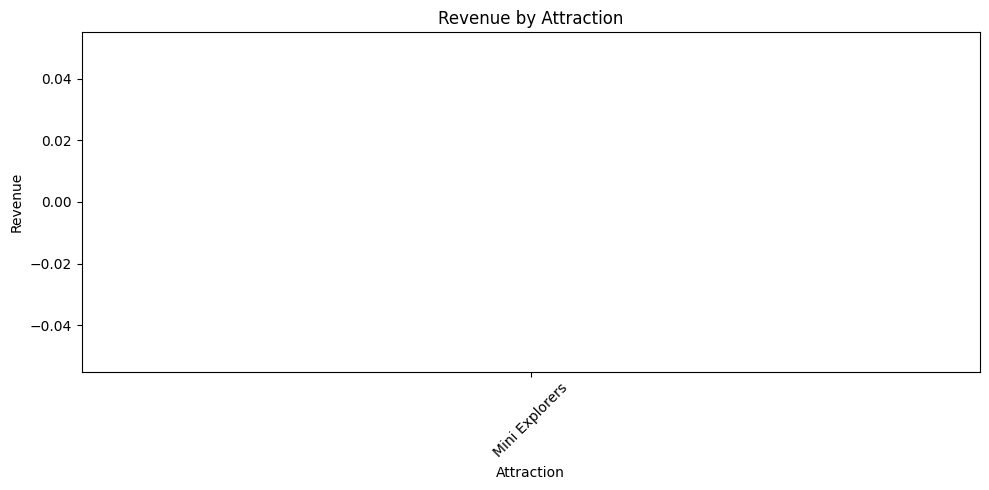

In [0]:
import matplotlib.pyplot as plt

df = spark.sql("""
SELECT
    attraction_name,
    SUM(total_revenue) AS revenue
FROM gold_park_summary
GROUP BY attraction_name
ORDER BY revenue DESC
""").toPandas()

plt.figure(figsize=(10,5))
plt.bar(df["attraction_name"], df["revenue"])
plt.xticks(rotation=45)
plt.title("Revenue by Attraction")
plt.xlabel("Attraction")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

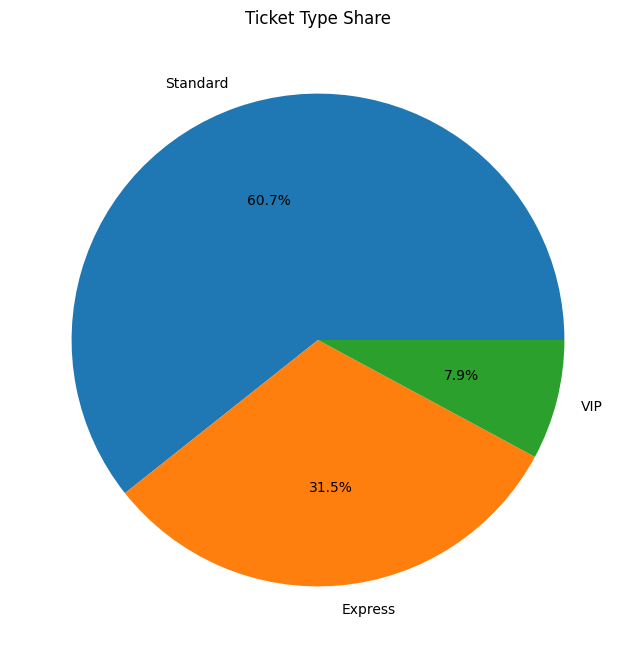

In [0]:
import matplotlib.pyplot as plt

df = spark.sql("""
SELECT
    ticket_type,
    COUNT(*) AS ticket_count
FROM silver_entries
GROUP BY ticket_type
""").toPandas()

plt.figure(figsize=(8,8))
plt.pie(
    df["ticket_count"],
    labels=df["ticket_type"],
    autopct="%1.1f%%"
)
plt.title("Ticket Type Share")
plt.show()


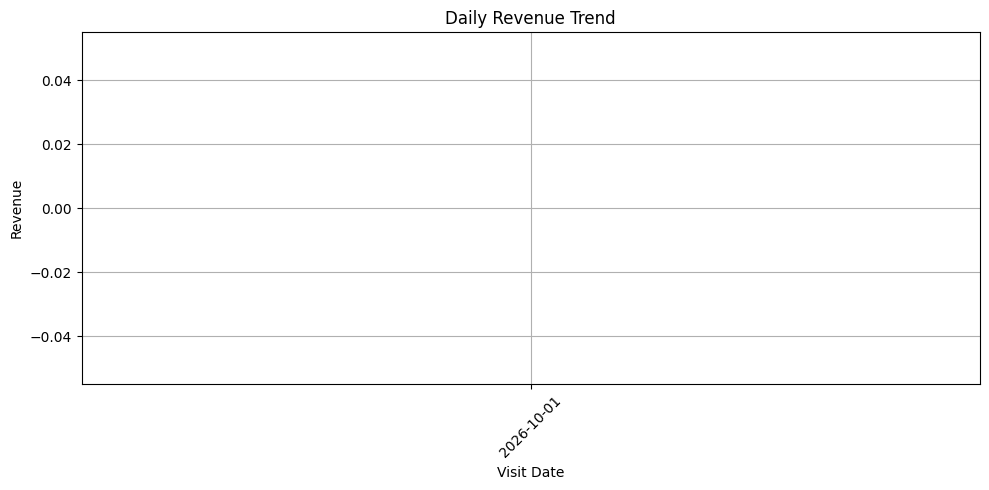

In [0]:
import matplotlib.pyplot as plt

df = spark.sql("""
SELECT
    visit_date,
    SUM(revenue) AS daily_revenue
FROM silver_entries
GROUP BY visit_date
ORDER BY visit_date
""").toPandas()

plt.figure(figsize=(10,5))
plt.plot(
    df["visit_date"],
    df["daily_revenue"],
    marker="o"
)

plt.title("Daily Revenue Trend")
plt.xlabel("Visit Date")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

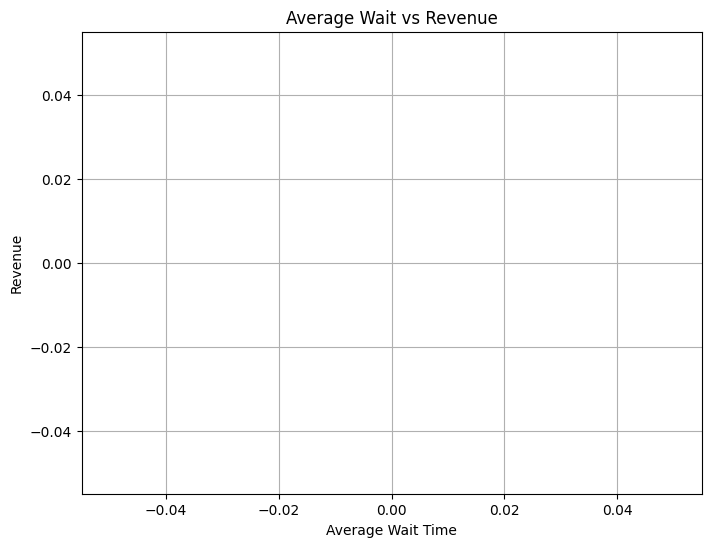

In [0]:
import matplotlib.pyplot as plt

df = spark.sql("""
SELECT
    attraction_name,
    avg_wait_time,
    total_revenue
FROM gold_park_summary
""").toPandas()

plt.figure(figsize=(8,6))

plt.scatter(
    df["avg_wait_time"],
    df["total_revenue"],
    s=100
)

for i in range(len(df)):
    plt.annotate(
        df["attraction_name"][i],
        (
            df["avg_wait_time"][i],
            df["total_revenue"][i]
        )
    )

plt.title("Average Wait vs Revenue")
plt.xlabel("Average Wait Time")
plt.ylabel("Revenue")
plt.grid(True)
plt.show()

In [0]:
%sql
SELECT * 
FROM gold_park_summary;


attraction_name,zone,total_entries,total_revenue,avg_wait_time
Mini Explorers,East,13,null,32.31
Crystal Maze,South,9,null,34.44
Forest Flyers,West,8,null,36.88
Pirate Voyage,East,9,null,30.0
Moonlight Train,West,12,null,30.42
Jungle Rapids,South,6,null,17.5
Coral Carousel,East,5,null,40.0
Galaxy Theater,North,7,null,35.0
Meteor Drop,North,10,null,19.5
Sky Spinner,North,9,null,44.44


In [0]:
%sql
SELECT *
FROM silver_entries
LIMIT 10;

entry_id,attraction_id,visit_date,ticket_type,ticket_price,status,wait_minutes,ticket_revenue,visitor_id,booking_channel,revenue
1002,A01,2026-10-10,Standard,350.0,Completed,65,350.0,null,null,null
1003,A04,2026-10-11,Standard,350.0,Completed,40,350.0,null,null,null
1004,A05,2026-10-15,Express,650.0,Completed,20,650.0,null,null,null
1005,A07,2026-10-07,Standard,350.0,Completed,5,350.0,null,null,null
1006,A08,2026-10-09,VIP,900.0,Completed,10,900.0,null,null,null
1007,A08,2026-10-14,Standard,350.0,Completed,5,350.0,null,null,null
1008,A06,2026-10-01,Express,650.0,Completed,40,650.0,null,null,null
1009,A02,2026-10-16,Standard,350.0,Completed,10,350.0,null,null,null
1013,A09,2026-10-11,Standard,350.0,Completed,15,350.0,null,null,null
1014,A07,2026-10-01,VIP,900.0,Completed,65,900.0,null,null,null


In [0]:
%sql
CREATE OR REPLACE TABLE silver_entries AS
SELECT
    *,
    ticket_price AS revenue
FROM tp_entries_work
WHERE status = 'Completed'
  AND ticket_price > 0
  AND wait_minutes >= 0;

---------------------------------------------------------------------------
AnalysisException                         Traceback (most recent call last)
File <command-6248689947103091>, line 1
----> 1 get_ipython().run_cell_magic('sql', '', "CREATE OR REPLACE TABLE silver_entries AS\nSELECT\n    *,\n    ticket_price AS revenue\nFROM tp_entries_work\nWHERE status = 'Completed'\n  AND ticket_price > 0\n  AND wait_minutes >= 0;\n")

File /databricks/python/lib/python3.12/site-packages/IPython/core/interactiveshell.py:2565, in InteractiveShell.run_cell_magic(self, magic_name, line, cell)
   2563 with self.builtin_trap:
   2564     args = (magic_arg_s, cell)
-> 2565     result = fn(*args, **kwargs)
   2567 # The code below prevents the output from being displayed
   2568 # when using magics with decorator @output_can_be_silenced
   2569 # when the last Python token in the expression is a ';'.
   2570 if getattr(fn, magic.MAGIC_OUTPUT_CAN_BE_SILENCED, False):

File /databricks/python_shell/li